# AI vs manual tags

In [1]:
"""Compares the team's manual trait scores (Google Sheet tab 'Manual Tagging': one row per trait, one column per video,
headed by the video title) with the LLM scores in youtube.llm_tagged for the same videos."""
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery

sys.path.insert(0, os.path.abspath("../src"))
import config
from sheet import read_rows
from traits import get_traits

RED, ACCENT, GRAY = "#990000", "#C44545", "#C9C9C9"

## Load manual scores and match titles to video ids

In [2]:
traits = get_traits()
trait_by_column = {trait["column"]: trait for trait in traits}
rows = read_rows("Manual Tagging")
header = rows[0]
dataset = f"{config.GCP_PROJECT_ID}.{config.BQ_DATASET}"
client = bigquery.Client(project=config.GCP_PROJECT_ID, location=config.BQ_LOCATION)
df_titles = client.query(f"SELECT id, snippet_title AS title, snippet_channelTitle AS channel FROM `{dataset}.videos`").to_dataframe()
df_titles["title_key"] = df_titles["title"].str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()

manual_rows = []
for column_index, title in enumerate(header):
    if column_index < 2 or not title.strip():
        continue
    for row in rows[1:]:
        trait = trait_by_column.get(re.sub(r"[^a-z0-9]+", "_", row[0].lower()).strip("_")) if row else None
        value = row[column_index].strip() if len(row) > column_index else ""
        if trait and re.fullmatch(r"[0-4]", value):
            manual_rows.append({"title": title.strip(), "column": trait["column"], "category": trait["category"],
                                "scale": trait["scale"], "human": int(value)})
df_manual = pd.DataFrame(manual_rows)
df_manual["title_key"] = df_manual["title"].str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()
df_manual = df_manual.merge(df_titles.drop_duplicates("title_key")[["title_key", "id", "channel"]], on="title_key", how="left")
print("manual videos and their match in BigQuery videos:")
df_manual.groupby("title", sort=False)[["id", "channel"]].first()

/private/tmp/claude-501/-Users-leoyang-Downloads-Github-Repos-DSO-585-project/c234077b-c684-4e3e-a33f-865c0d53ac7a/scratchpad/venv/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


manual videos and their match in BigQuery videos:


,id,channel
title,,
I Bought An Abandoned Church For $45K & Spent $194K Making It A Home,NaN,NaN
The Housing Market Is Completely F*d,BWNOdHB8TKA,Graham Stephan
"Last Cheater Standing Wins $10,000",_L1Rim7-IPo,Mark Rober
My Dogs Ordered 100 Buckets of Chicken!,QX3txldu5h4,Tucker Budzyn
The Most Unexplored Places On Earth,bdK8Hckw3CI,Trust Me Bro
Online Couples Meet for the First Time I Truth or Drink I Cut,qdX3WEoo5x0,Cut


## Join the LLM scores

In [3]:
trait_cols = [trait["column"] for trait in traits]
df_ai = client.query(f"""
    SELECT id, tagged_at, {", ".join(trait_cols)} FROM `{dataset}.llm_tagged`
    WHERE id IN UNNEST(@ids)
""", job_config=bigquery.QueryJobConfig(query_parameters=[
    bigquery.ArrayQueryParameter("ids", "STRING", df_manual["id"].dropna().unique().tolist())])).to_dataframe()
df_ai_long = df_ai.melt(id_vars=["id", "tagged_at"], value_vars=trait_cols, var_name="column", value_name="ai")
df_pairs = df_manual.merge(df_ai_long, on=["id", "column"])
print(f"{df_pairs['id'].nunique()} videos with both manual and AI scores, {len(df_pairs)} trait scores compared")
print("not compared:", df_manual.loc[~df_manual["id"].isin(df_ai["id"]), "title"].unique().tolist())

/private/tmp/claude-501/-Users-leoyang-Downloads-Github-Repos-DSO-585-project/c234077b-c684-4e3e-a33f-865c0d53ac7a/scratchpad/venv/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


5 videos with both manual and AI scores, 395 trait scores compared
not compared: ['I Bought An Abandoned Church For $45K & Spent $194K Making It A Home']


## Agreement metrics

In [4]:
"""Exact: same score. Within 1: scores differ by at most 1 point. MAE: mean absolute score difference.
Presence: a trait counts as present when its score is >= 1; precision/recall/F1 treat the manual tag as the truth.
'All zeros' is a reference: how often a tagger that scores every trait 0 would match the manual tags exactly."""
def agreement(df_scope):
    human_present = df_scope["human"] >= 1
    ai_present = df_scope["ai"] >= 1
    precision = (human_present & ai_present).sum() / max(ai_present.sum(), 1)
    recall = (human_present & ai_present).sum() / max(human_present.sum(), 1)
    return pd.Series({
        "n_scores": len(df_scope),
        "exact": (df_scope["human"] == df_scope["ai"]).mean(),
        "within_1": ((df_scope["human"] - df_scope["ai"]).abs() <= 1).mean(),
        "MAE": (df_scope["human"] - df_scope["ai"]).abs().mean(),
        "presence_agree": (human_present == ai_present).mean(),
        "precision": precision,
        "recall": recall,
        "F1": 2 * precision * recall / max(precision + recall, 1e-9),
        "all_zeros_exact": (df_scope["human"] == 0).mean(),
        "mean_gap_ai_minus_human": (df_scope["ai"] - df_scope["human"]).mean(),
    })


df_overall = pd.DataFrame({"all traits": agreement(df_pairs),
                           "0-4 traits": agreement(df_pairs[df_pairs["scale"] == "linear"]),
                           "0/1 traits": agreement(df_pairs[df_pairs["scale"] == "binary"])}).T
df_overall.round(2)

,n_scores,exact,within_1,MAE,presence_agree,precision,recall,F1,all_zeros_exact,mean_gap_ai_minus_human
all traits,395.0,0.64,0.86,0.55,0.83,0.70,0.83,0.76,0.68,0.30
0-4 traits,375.0,0.64,0.86,0.55,0.83,0.70,0.83,0.76,0.68,0.33
0/1 traits,20.0,0.60,0.85,0.60,0.80,0.62,0.83,0.71,0.70,-0.30


In [5]:
df_by_video = df_pairs.groupby(["title", "channel"]).apply(agreement).round(2)
df_by_video

,,n_scores,exact,within_1,MAE,presence_agree,precision,recall,F1,all_zeros_exact,mean_gap_ai_minus_human
title,channel,,,,,,,,,,
"Last Cheater Standing Wins $10,000",Mark Rober,79.0,0.56,0.86,0.59,0.84,0.81,0.83,0.82,0.56,0.32
My Dogs Ordered 100 Buckets of Chicken!,Tucker Budzyn,79.0,0.61,0.73,0.81,0.75,0.58,0.62,0.60,0.70,0.25
Online Couples Meet for the First Time I Truth or Drink I Cut,Cut,79.0,0.73,0.89,0.46,0.85,0.59,0.94,0.73,0.78,0.23
The Housing Market Is Completely F*d,Graham Stephan,79.0,0.59,0.91,0.51,0.87,0.83,0.83,0.83,0.63,0.33
The Most Unexplored Places On Earth,Trust Me Bro,79.0,0.71,0.90,0.41,0.85,0.65,1.00,0.79,0.72,0.38


In [6]:
df_by_category = df_pairs.groupby("category").apply(agreement).sort_values("MAE").round(2)
df_by_category

,n_scores,exact,within_1,MAE,presence_agree,precision,recall,F1,all_zeros_exact,mean_gap_ai_minus_human
category,,,,,,,,,,
Format,165.0,0.79,0.89,0.36,0.88,0.68,0.72,0.70,0.81,0.15
Subject Matter,75.0,0.73,0.91,0.40,0.85,0.48,1.00,0.65,0.87,0.40
Tone and Emotion,55.0,0.45,0.84,0.78,0.71,0.57,0.80,0.67,0.64,0.49
Audience Hooks,50.0,0.50,0.76,0.84,0.80,0.77,0.83,0.80,0.52,0.24
Production,50.0,0.36,0.80,0.88,0.80,0.86,0.90,0.88,0.18,0.52


## Charts

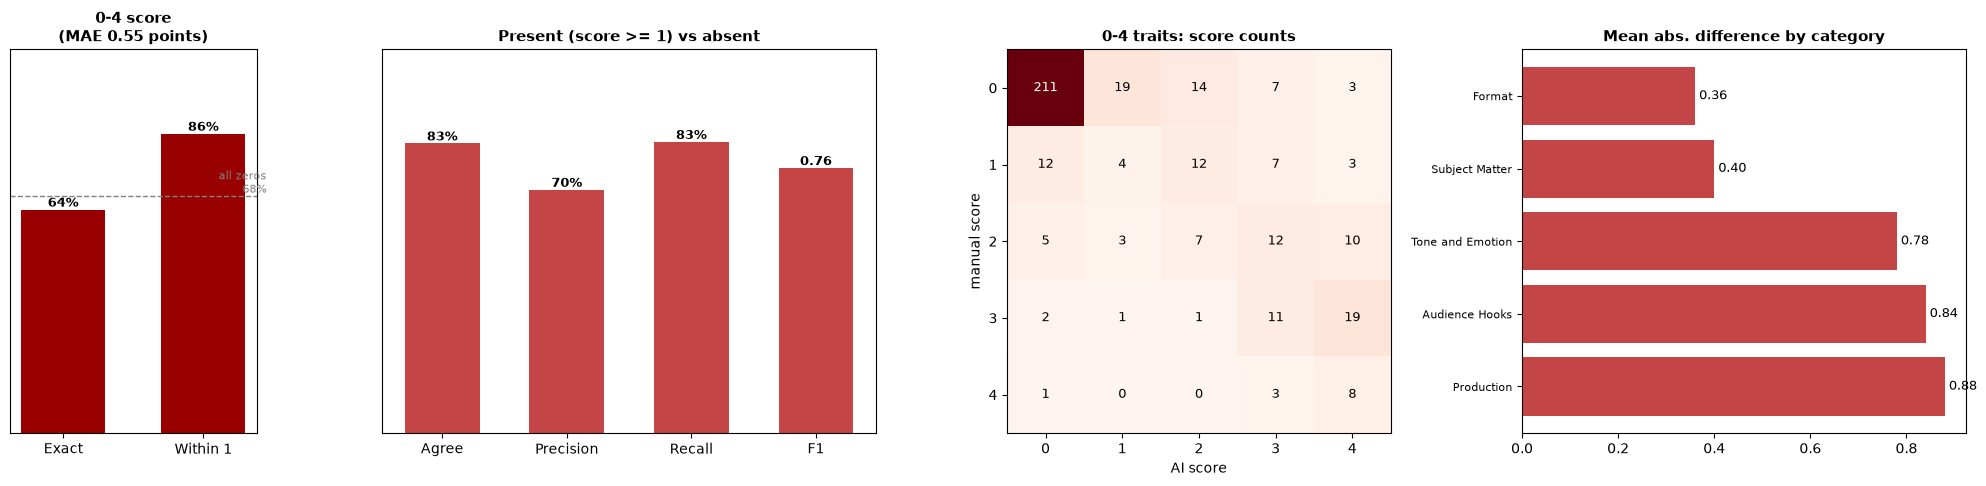

In [7]:
"""Two different questions, so two panels: (1) on the 0-4 score, how close is the AI to the manual tag?
(2) collapsing each score to present (>= 1) / absent, does the AI find the same traits? Precision/recall/F1 treat the
manual tag as the truth."""
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), gridspec_kw={"width_ratios": [2, 4, 3.2, 3.6]})
overall = df_overall.loc["all traits"]

score_values = [overall["exact"], overall["within_1"]]
axes[0].bar(["Exact", "Within 1"], score_values, color=RED, width=0.6)
axes[0].axhline(overall["all_zeros_exact"], color="gray", linestyle="--", linewidth=1)
axes[0].text(1.45, overall["all_zeros_exact"], f"all zeros\n{overall['all_zeros_exact']:.0%}", fontsize=8, color="gray", va="bottom", ha="right")
for position, value in enumerate(score_values):
    axes[0].text(position, value, f"{value:.0%}", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, 1.1)
axes[0].set_yticks([])
axes[0].set_title(f"0-4 score\n(MAE {overall['MAE']:.2f} points)", fontsize=11, fontweight="bold")

presence_values = [overall["presence_agree"], overall["precision"], overall["recall"], overall["F1"]]
axes[1].bar(["Agree", "Precision", "Recall", "F1"], presence_values, color=ACCENT, width=0.6)
for position, value in enumerate(presence_values):
    axes[1].text(position, value, f"{value:.0%}" if position < 3 else f"{value:.2f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_ylim(0, 1.1)
axes[1].set_yticks([])
axes[1].set_title("Present (score >= 1) vs absent", fontsize=11, fontweight="bold")

df_linear = df_pairs[df_pairs["scale"] == "linear"]
df_confusion = pd.crosstab(df_linear["human"], df_linear["ai"]).reindex(index=range(5), columns=range(5), fill_value=0)
axes[2].imshow(df_confusion, cmap="Reds")
for human_score in range(5):
    for ai_score in range(5):
        count = df_confusion.loc[human_score, ai_score]
        axes[2].text(ai_score, human_score, count, ha="center", va="center", fontsize=9,
                     color="white" if count > df_confusion.to_numpy().max() / 2 else "black")
axes[2].set_xticks(range(5))
axes[2].set_yticks(range(5))
axes[2].set_xlabel("AI score")
axes[2].set_ylabel("manual score")
axes[2].set_title("0-4 traits: score counts", fontsize=11, fontweight="bold")

axes[3].barh(df_by_category.index, df_by_category["MAE"], color=ACCENT)
for position, value in enumerate(df_by_category["MAE"]):
    axes[3].text(value, position, f" {value:.2f}", va="center", fontsize=9)
axes[3].invert_yaxis()
axes[3].set_title("Mean abs. difference by category", fontsize=11, fontweight="bold")
axes[3].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

## Largest disagreements

In [8]:
df_pairs.assign(gap=(df_pairs["ai"] - df_pairs["human"])).loc[lambda df: df["gap"].abs() >= 2] \
    .sort_values("gap", key=abs, ascending=False)[["title", "column", "human", "ai", "gap"]].head(25)

,title,column,human,ai,gap
391,Online Couples Meet for the First Time I Truth...,lifestyle_personal_life,0,4,4
212,My Dogs Ordered 100 Buckets of Chicken!,promotional,4,0,-4
178,My Dogs Ordered 100 Buckets of Chicken!,skit,0,4,4
173,My Dogs Ordered 100 Buckets of Chicken!,prank,0,4,4
296,The Most Unexplored Places On Earth,curiosity_gap_hook,0,3,3
202,My Dogs Ordered 100 Buckets of Chicken!,production,1,4,3
197,My Dogs Ordered 100 Buckets of Chicken!,suspense_cliffhanger,0,3,3
217,My Dogs Ordered 100 Buckets of Chicken!,curiosity_gap_hook,1,4,3
190,My Dogs Ordered 100 Buckets of Chicken!,haul_shopping,0,3,3
163,My Dogs Ordered 100 Buckets of Chicken!,review,3,0,-3


## Save results

In [9]:
output_dir = os.path.dirname(config.MODEL_MATRIX_PATH)
df_overall.to_csv(os.path.join(output_dir, "agreement_overall.csv"))
df_by_category.to_csv(os.path.join(output_dir, "agreement_by_category.csv"))
df_confusion.to_csv(os.path.join(output_dir, "agreement_confusion.csv"))
print("saved to", output_dir)

saved to /Users/leoyang/Downloads/Github Repos/DSO_585_project/data/processed
